# M05 · XGBoost

Entrenamos un clasificador **XGBoost** para predecir el grupo NOVA (1 a 4) de un producto.

**Objetivo:** macro F1 lo más alto posible, con un gap entre train y validación **< 5 %**.

## Paso 1 · Carga de datos

Partimos del fichero limpio `off_nova_clean.csv.gz` (lo generó el EDA). **No lo modificamos nunca**: cualquier transformación propia de este modelo irá dentro de un pipeline más adelante.

In [22]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA = Path("data/processed/off_nova_clean.csv.gz")
if not DATA.exists():  # Jupyter lanzado desde notebooks/
    DATA = Path("../data/processed/off_nova_clean.csv.gz")

df = pd.read_csv(DATA, dtype={"code": str})
df.shape

(48119, 35)

## Paso 2 · Separar train y test

La columna `split` ya viene marcada en el fichero (80 % train, 20 % test). La usamos tal cual para que todos los modelos del equipo comparen con los mismos datos.

Separamos **antes de explorar nada**. El test queda guardado y no lo miramos: solo se usa una vez, al final, en M08, para la nota final del modelo elegido.

In [23]:
train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

In [24]:
print("train:", train.shape)
print("test:", test.shape)

train: (38495, 35)
test: (9624, 35)


## Paso 3 · Definir X, y y los grupos (solo train)

- `y` es lo que queremos predecir: `nova_group`.
- `X` son las variables con las que el modelo predice. Quitamos columnas que no son features:
  - `code`, `product_name`, `brands`, `ingredients_text`: identificadores o texto libre.
  - `split`: solo sirve para separar.
  - `nova_group`: es la respuesta; si la dejamos en `X`, el modelo hace trampa.
  - `grupo_producto`: lo guardamos aparte en `groups`. No es una feature, pero lo necesita la validación cruzada para que un mismo producto (mismo nombre y marca, varias filas casi iguales) no caiga a la vez en train y en validación. Sin eso, el score saldría inflado.

In [25]:
NOT_FEATURES = ["code", "product_name", "brands", "ingredients_text",
                "split", "nova_group", "grupo_producto"]

y = train["nova_group"]
groups = train["grupo_producto"]
X = train.drop(columns=NOT_FEATURES)

In [26]:
print("X:", X.shape)
print(list(X.columns))
print()
print(y.value_counts().sort_index())
print()
print(y.value_counts(normalize=True).sort_index().round(3))

X: (38495, 28)
['additives_n', 'pnns_groups_1', 'pnns_groups_2', 'energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'fruits-vegetables-legumes_100g', 'sin_lista_ingredientes', 'tiene_aromas', 'tiene_edulcorantes', 'tiene_jarabes', 'tiene_almidon_modificado', 'tiene_grasa_hidrogenada', 'tiene_proteina_aislada', 'tiene_colorantes', 'tiene_emulsionantes', 'tiene_potenciadores', 'tiene_aceite_palma', 'tiene_conservantes', 'tiene_sal', 'tiene_azucar', 'tiene_aceite', 'n_ingredientes']

nova_group
1     4952
2     4308
3     7865
4    21370
Name: count, dtype: int64

nova_group
1    0.129
2    0.112
3    0.204
4    0.555
Name: proportion, dtype: float64


### Resultados

- `X` tiene 38.495 filas y 28 columnas: son los productos de train y las variables con las que el modelo va a predecir.
- Hay 4 clases NOVA. La clase 4 tiene 21.370 productos (55,5 %); las otras son mucho más pequeñas: NOVA 3 con 20,4 %, NOVA 1 con 12,9 % y NOVA 2 con 11,2 %.
- Las clases están **desbalanceadas**. Un modelo que dijera siempre "NOVA 4" acertaría más de la mitad de las veces sin aprender nada. Por eso la métrica principal es **macro F1** (que da el mismo peso a cada clase) y no accuracy, y por eso miraremos el recall de cada clase, sobre todo de NOVA 2, que es la más pequeña.

## Paso 4 · Preparar las columnas

XGBoost trabaja bien con los datos casi tal cual, así que aquí hay poco que transformar:
- **Valores vacíos (nulos): NO los rellenamos.** XGBoost los maneja solo: en cada división del árbol aprende a qué lado mandar los vacíos. Además, que falte un dato es información útil (por ejemplo, a `fiber_100g` le falta el 78 % en NOVA 2: aceites, miel, azúcar). Si lo rellenáramos con la mediana, perderíamos esa señal. *(Decisión de M05; difiere de la imputación con mediana de otros modelos que sí la necesitan.)*
- **Binarias (0/1)**: se dejan tal cual.
- **Categoría `pnns_groups_2`**: **no usamos One-Hot**. XGBoost trata las categorías internamente (`enable_categorical=True`), así que la columna se queda como una sola, con el tipo `category` de pandas. Así no creamos ~40 columnas y la importancia de variables (y SHAP) se lee por columna original. Usamos `pnns_groups_2` y no `pnns_groups_1` (decisión del equipo en el EDA).
- **No hacemos escalado ni log**: XGBoost usa árboles y no los necesita.
- Excluimos `tiene_grasa_hidrogenada` (solo el 0,5 % de los productos).

Como no calculamos nada a partir de los datos (ni medianas, ni medias), **no hay riesgo de fuga de datos** y no hace falta un `ColumnTransformer`: basta con elegir las columnas.

### 4.1 Grupos de columnas

Clasificamos las columnas en tres listas:

- `cat_cols`: la columna de texto con una categoría (`pnns_groups_2`).
- `num_cols`: las 11 columnas numéricas continuas (nutrientes incluida la fibra, aditivos, nº de ingredientes). Pueden tener nulos y los dejamos así.
- `bin_cols`: las columnas 0/1 (`tiene_*` y `sin_lista_ingredientes`). Excluimos `tiene_grasa_hidrogenada`.

Después nos quedamos solo con esas columnas en `X`. `pnns_groups_1` y `tiene_grasa_hidrogenada` no están en ninguna lista, así que desaparecen.

In [27]:
cat_cols = ["pnns_groups_2"]
num_cols = ["additives_n", "energy-kcal_100g", "fat_100g", "saturated-fat_100g",
            "carbohydrates_100g", "sugars_100g", "fiber_100g", "proteins_100g",
            "salt_100g", "fruits-vegetables-legumes_100g", "n_ingredientes"]
bin_cols = [c for c in X.columns
            if c.startswith("tiene_") and c != "tiene_grasa_hidrogenada"] + ["sin_lista_ingredientes"]

X = X[cat_cols + num_cols + bin_cols]

print(len(cat_cols), len(num_cols), len(bin_cols))
print(X.shape)

1 11 14
(38495, 26)


### Resultados

- Salen 1, 11 y 14 columnas en cada grupo: 26 columnas en total. Las otras 2 de las 28 de `X` (`pnns_groups_1` y `tiene_grasa_hidrogenada`) quedan fuera a propósito.

### 4.2 Columna categórica: tipo `category`

XGBoost puede tratar las categorías internamente (`enable_categorical=True`), así que `pnns_groups_2` se queda como **una sola columna**, pero tiene que tener el tipo `category` de pandas (no texto normal).

Ventajas: no creamos ~40 columnas y la importancia de variables (y SHAP) se lee por columna original.

Ojo: las categorías se definen con train. Habrá que reutilizar la misma lista al evaluar con el test (M08).

In [28]:
X["pnns_groups_2"] = X["pnns_groups_2"].astype("category")

X["pnns_groups_2"].dtype

CategoricalDtype(categories=['Alcoholic beverages', 'Appetizers',
                  'Artificially sweetened beverages', 'Baby foods',
                  'Baby milks', 'Biscuits and cakes', 'Bread',
                  'Breakfast cereals', 'Cereals', 'Cheese',
                  'Chocolate products', 'Dairy desserts',
                  'Dressings and sauces', 'Dried fruits', 'Eggs', 'Fats',
                  'Fish and seafood', 'Fruit juices', 'Fruit nectars',
                  'Fruits', 'Ice cream', 'Legumes', 'Meat', 'Milk and yogurt',
                  'Nuts', 'Offals', 'One-dish meals', 'Pastries',
                  'Pizza pies and quiches', 'Plant-based milk substitutes',
                  'Potatoes', 'Processed meat', 'Salty and fatty products',
                  'Sandwiches', 'Soups', 'Sweetened beverages', 'Sweets',
                  'Teas and herbal teas and coffees', 'Unsweetened beverages',
                  'Vegetables', 'Waters and flavored waters', 'unknown'],
, ordered=False,

### Resultados

- `pnns_groups_2` ahora es de tipo `category` con 42 categorías.

### 4.3 Comprobamos los nulos

Verificamos qué columnas tienen valores vacíos. Los dejamos tal cual: XGBoost los gestiona solo.

In [29]:
nulos = X.isna().sum()
nulos[nulos > 0].sort_values(ascending=False)

fiber_100g                        12928
fruits-vegetables-legumes_100g     4314
saturated-fat_100g                 1178
sugars_100g                        1082
salt_100g                          1079
fat_100g                            800
proteins_100g                       793
carbohydrates_100g                  789
energy-kcal_100g                    482
additives_n                           3
n_ingredientes                        2
dtype: int64

## Paso 5 · Etiquetas, pesos, folds y modelo

### 5.1 Etiquetas de 0 a 3

XGBoost exige que las clases empiecen en 0, y las nuestras van de 1 a 4 (NOVA 1 a 4). Creamos `y_xgb = y - 1` (valores 0, 1, 2, 3). Guardamos `y` original para las métricas.

In [30]:
y_xgb = y - 1

y_xgb.value_counts().sort_index()

nova_group
0     4952
1     4308
2     7865
3    21370
Name: count, dtype: int64

### Resultados

- Las clases ahora son 0, 1, 2, 3 (= NOVA 1, 2, 3, 4), con los mismos conteos que antes. Por ejemplo, la clase 3 (NOVA 4) sigue teniendo 21.370 productos.

### 5.2 Pesos por producto

Como NOVA 4 es el 55 % de los datos, el modelo tiende a ignorar las clases pequeñas. Para evitarlo damos a cada producto un **peso** inversamente proporcional al tamaño de su clase: más peso a los NOVA 1 y 2 (pocos productos), menos a los NOVA 4 (muchos). Así un error en una clase pequeña "cuesta" más durante el entrenamiento.

`compute_sample_weight("balanced", y_xgb)` calcula un peso por cada producto. Después comprobamos el peso de cada clase.

In [31]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weight = compute_sample_weight("balanced", y_xgb)

pd.Series(sample_weight).groupby(y_xgb.values).first().round(2)

0    1.94
1    2.23
2    1.22
3    0.45
dtype: float64

### Resultados

- Cada clase recibe un único peso: 1,94 para NOVA 1, 2,23 para NOVA 2, 1,22 para NOVA 3 y 0,45 para NOVA 4.
- Un producto de NOVA 2 pesa casi 5 veces más que uno de NOVA 4 (2,23 / 0,45). Así el modelo no puede ignorar las clases pequeñas: equivocarse en un NOVA 2 "cuesta" 5 veces más que equivocarse en un NOVA 4.

### 5.3 Definir los folds

Usamos `StratifiedGroupKFold`, la misma validación que el resto del equipo:
- **Stratified**: cada fold mantiene más o menos el mismo porcentaje de cada clase NOVA que train.
- **Group**: todas las filas con el mismo `grupo_producto` caen siempre en el mismo fold. Sin esto, el mismo producto (con varias filas casi iguales) estaría a la vez en entrenamiento y en validación, y la nota saldría inflada.
- `n_splits=3`: 3 folds. `shuffle=True` y `random_state=42`: se mezclan los datos, pero de forma repetible.

Los necesitamos **antes** de buscar hiperparámetros: Optuna evalúa cada prueba con estos mismos folds.

Esta celda solo define los folds. Después comprobamos que se han hecho bien.

In [32]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

for i, (idx_tr, idx_va) in enumerate(cv.split(X, y_xgb, groups), start=1):
    pct = (y.iloc[idx_va].value_counts(normalize=True).sort_index() * 100).round(1)
    compartidos = len(set(groups.iloc[idx_tr]) & set(groups.iloc[idx_va]))
    print(f"Fold {i}: train={len(idx_tr)}, validación={len(idx_va)}")
    print(f"   % por clase NOVA 1-4 en validación: {pct.tolist()}")
    print(f"   grupos que aparecen en train y en validación: {compartidos}")

Fold 1: train=25663, validación=12832
   % por clase NOVA 1-4 en validación: [12.9, 11.2, 20.4, 55.5]
   grupos que aparecen en train y en validación: 0
Fold 2: train=25664, validación=12831
   % por clase NOVA 1-4 en validación: [12.9, 11.2, 20.4, 55.5]
   grupos que aparecen en train y en validación: 0
Fold 3: train=25663, validación=12832
   % por clase NOVA 1-4 en validación: [12.9, 11.2, 20.4, 55.5]
   grupos que aparecen en train y en validación: 0


### Resultados

- Los 3 folds tienen unas 12.830 filas de validación y unas 25.660 de entrenamiento.
- En cada fold los porcentajes por clase (12,9 / 11,2 / 20,4 / 55,5) son idénticos a los de train: la estratificación funciona, así que las 4 clases están bien representadas en todas las validaciones.
- **0 grupos compartidos** entre train y validación en los 3 folds: un mismo producto nunca está a la vez en entrenamiento y en validación, así que la nota no estará inflada por duplicados.

### 5.4 Búsqueda de hiperparámetros con Optuna

Hasta ahora no hemos elegido los hiperparámetros del modelo (profundidad de los árboles, número de árboles, etc.). **Optuna** los busca por nosotros: prueba muchas combinaciones y se queda con la mejor.

Cada combinación (una *prueba* o *trial*) se evalúa con la misma validación cruzada de 5.3 (macro F1, folds agrupados, pesos de 5.2). Así todas las pruebas son comparables y la nota no sale inflada.

Pasos:
1. Definir los parámetros fijos y la función objetivo.
2. Lanzar unas pocas pruebas para medir el tiempo.
3. Lanzar la búsqueda completa.
4. Leer los resultados: mejores parámetros y qué hiperparámetros importan más.

#### Parámetros fijos

Algunos parámetros no los buscamos: ya los decidimos antes y no cambian entre pruebas. Los guardamos en un diccionario `FIXED` para reutilizarlos en cada prueba.

- `objective="multi:softprob"`: clasificación de 4 clases; devuelve una probabilidad por clase.
- `tree_method="hist"` y `enable_categorical=True`: necesarios para que XGBoost use `pnns_groups_2` como categoría nativa.
- `random_state=42`: para que los resultados se puedan repetir.
- `n_jobs=-1`: usa todos los núcleos del procesador.

Esta celda solo define el diccionario; no entrena nada.

In [33]:
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate

optuna.logging.set_verbosity(optuna.logging.WARNING)

FIXED = dict(
    objective="multi:softprob",
    tree_method="hist",
    enable_categorical=True,
    random_state=42,
    n_jobs=-1,
)


#### Función objetivo

Optuna llama a esta función una vez por prueba (*trial*). En cada una:
1. propone valores para 9 hiperparámetros (`trial.suggest_*`);
2. crea un `XGBClassifier` con los parámetros fijos (`FIXED`) más los propuestos;
3. lo evalúa con la validación cruzada de 5.3 y devuelve el **macro F1 de validación** (media de los 3 folds), que Optuna intenta maximizar;
4. guarda el **gap** (train − validación) de esa prueba, para descartar después las que superen el 5 %.

Los 9 hiperparámetros y por qué los buscamos:

| Hiperparámetro | Qué controla | Rango |
|---|---|---|
| `n_estimators` | número de árboles | 100 – 600 |
| `learning_rate` | cuánto corrige cada árbol (bajo = más lento y más prudente) | 0,01 – 0,3 (escala log) |
| `max_depth` | profundidad máxima de cada árbol (más profundo = más overfitting) | 3 – 10 |
| `min_child_weight` | peso mínimo en una hoja (más alto = hojas más prudentes) | 1 – 10 |
| `gamma` | mejora mínima para aceptar una división (más alto = menos divisiones) | 0 – 5 |
| `subsample` | fracción de filas que ve cada árbol | 0,5 – 1 |
| `colsample_bytree` | fracción de columnas que ve cada árbol | 0,5 – 1 |
| `reg_lambda` | regularización L2 (frena pesos grandes en las hojas) | 0,001 – 10 (escala log) |
| `reg_alpha` | regularización L1 (empuja pesos de hojas hacia 0) | 0,001 – 10 (escala log) |

`learning_rate`, `reg_lambda` y `reg_alpha` usan escala logarítmica (`log=True`): sus valores útiles van de muy pequeños a grandes, y así Optuna explora igual de bien todos los órdenes de magnitud.

Esta celda solo define la función; todavía no ejecuta ninguna prueba.

In [34]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    }
    m = XGBClassifier(**FIXED, **params)
    s = cross_validate(
        m, X, y_xgb,
        groups=groups, cv=cv,
        scoring="f1_macro",
        params={"sample_weight": sample_weight},
        return_train_score=True,
    )
    val = s["test_score"].mean()
    trial.set_user_attr("gap", s["train_score"].mean() - val)
    return val

#### Prueba rápida: 10 pruebas para medir el tiempo

Antes de lanzar la búsqueda completa, hacemos solo 10 pruebas. Cada prueba entrena 3 modelos (uno por fold), así que puede tardar. Con este test medimos cuánto dura una prueba y así sabemos cuántas podemos permitirnos.

- `create_study(direction="maximize")`: crea el «estudio». Maximizamos porque queremos el macro F1 más alto posible.
- `sampler=TPESampler(seed=42)`: el método con el que Optuna propone valores. La semilla 42 hace que la búsqueda se pueda repetir.
- `study.optimize(objective, n_trials=10)`: lanza 10 pruebas.

Este estudio es solo una medición de tiempo: luego creamos otro nuevo para la búsqueda de verdad.

In [35]:
import time
from optuna.samplers import TPESampler

study_test = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))

t0 = time.time()
study_test.optimize(objective, n_trials=10)
duracion = time.time() - t0

print(f"10 pruebas: {duracion / 60:.1f} min  ->  {duracion / 10 / 60:.1f} min por prueba")
study_test.trials_dataframe()[["number", "value", "user_attrs_gap", "params_n_estimators", "params_max_depth", "params_learning_rate"]].round(3)

10 pruebas: 1.7 min  ->  0.2 min por prueba


,number,value,user_attrs_gap,params_n_estimators,params_max_depth,params_learning_rate
0,0,0.960,0.017,287,8,0.254
1,1,0.955,0.007,454,10,0.011
2,2,0.956,0.008,316,7,0.027
3,3,0.954,0.005,357,3,0.075
4,4,0.951,0.005,252,8,0.014
5,5,0.955,0.005,431,7,0.029
6,6,0.958,0.017,399,3,0.230
7,7,0.952,0.004,278,7,0.026
8,8,0.948,0.003,102,8,0.160
9,9,0.949,0.003,412,3,0.031


### Resultados

- Las 10 pruebas tardaron 1,7 min en total (≈ 0,2 min por prueba, con 3 folds).
- El macro F1 va de 0,948 a 0,960 y el gap de 0,003 a 0,017: todas por debajo del 5 %.
- Las mejores pruebas (0 y 6) tienen un `learning_rate` alto (≈ 0,25); con valores bajos (0,01 – 0,03) y ~300-450 árboles el modelo aprende demasiado poco.
- Con ~10 s por prueba, 100 pruebas son asumibles (≈ 17 min estimados).

#### Búsqueda completa: 100 pruebas

Ahora sí lanzamos la búsqueda de verdad: 100 pruebas, con un estudio nuevo (`study`) distinto del de medición de tiempo (`study_test`).

- Al principio Optuna prueba valores casi al azar; después se concentra en las zonas que dieron mejor macro F1.
- `show_progress_bar=True` muestra una barra de progreso.
- Al final guardamos la duración y mostramos la mejor nota, su gap y los mejores hiperparámetros.

Ojo: `study.best_params` es la prueba con el macro F1 más alto, sin mirar el gap. En la siguiente celda comprobamos que su gap sea < 5 %.

In [39]:
study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))

t0 = time.time()
study.optimize(objective, n_trials=100, show_progress_bar=True)
duracion = time.time() - t0

print(f"100 pruebas: {duracion / 60:.1f} min")
print(f"Mejor macro F1 (3 folds): {study.best_value:.3f}")
print(f"Gap de esa prueba:        {study.best_trial.user_attrs['gap']:.3f}")
study.best_params

  0%|          | 0/100 [00:00<?, ?it/s]

100 pruebas: 10.6 min
Mejor macro F1 (3 folds): 0.964
Gap de esa prueba:        0.035


{'n_estimators': 270,
 'learning_rate': 0.24525130406866227,
 'max_depth': 10,
 'min_child_weight': 1,
 'gamma': 0.014806547188510905,
 'subsample': 0.9228592132275344,
 'colsample_bytree': 0.5447247015218646,
 'reg_lambda': 2.1898216536683943,
 'reg_alpha': 0.08897202593486664}

### Resultados

- Las 100 pruebas tardaron 10,6 min (unos 5,5 s por prueba, con 3 folds).
- La mejor prueba (nº 93) tiene macro F1 = 0,964 y gap = 0,035, por debajo del 5 %. Sus hiperparámetros están en el borde de los rangos: `max_depth` = 10 (el máximo) y `min_child_weight` = 1 (el mínimo). Es un modelo complejo, con árboles profundos y hojas pequeñas.
- XGBoost con los hiperparámetros iniciales, medido con los mismos 3 folds en el 6.3, saca 0,963: la mejora de los hiperparámetros de Optuna es de apenas 0,001, dentro del ruido (± 0,001). Los iniciales ya estaban cerca del techo.

#### Las mejores pruebas: macro F1 y gap

La mejor prueba por macro F1 no tiene por qué ser la mejor elección: si tiene un gap alto, el modelo está más cerca de memorizar. Por eso miramos las 10 mejores pruebas juntas, con su gap.

- `trials_dataframe()` convierte las 100 pruebas en una tabla (una fila por prueba).
- Nos quedamos solo con las que cumplen el límite del equipo (gap < 5 %).
- Las ordenamos por macro F1, de más alto a más bajo, y mostramos las 10 primeras.

In [40]:
trials = study.trials_dataframe()
trials = trials.rename(columns={"value": "f1_val", "user_attrs_gap": "gap"})

ok = trials[trials["gap"] < 0.05].sort_values("f1_val", ascending=False)

print(f"Pruebas con gap < 5 %: {len(ok)} de {len(trials)}")
ok[["number", "f1_val", "gap", "params_n_estimators", "params_max_depth",
    "params_min_child_weight", "params_learning_rate"]].head(10).round(3)

Pruebas con gap < 5 %: 100 de 100


,number,f1_val,gap,params_n_estimators,params_max_depth,params_min_child_weight,params_learning_rate
93,93,0.964,0.035,270,10,1,0.245
81,81,0.964,0.035,217,10,2,0.180
95,95,0.964,0.032,274,10,1,0.295
70,70,0.964,0.031,247,10,2,0.227
67,67,0.964,0.031,232,10,3,0.271
57,57,0.964,0.036,227,10,2,0.161
65,65,0.964,0.035,226,10,3,0.164
63,63,0.964,0.033,210,10,1,0.166
96,96,0.964,0.028,255,10,3,0.222
89,89,0.964,0.036,235,10,2,0.190


### Resultados

- Las 100 pruebas cumplen el límite del equipo (gap < 5 %).
- Las 10 mejores empatan en macro F1 (0,964); las diferencias son menores que el ruido entre folds. Por eso podemos elegir por gap.
- Todas tienen `max_depth` = 10, el límite superior de nuestro rango, con `min_child_weight` entre 1 y 3 y `learning_rate` alto (0,16 – 0,30). No ampliamos `max_depth`: con 10 el gap ya está en ~3 % y la ganancia esperada es menor que el ruido.
- La prueba 96 tiene el gap más bajo de las 10 (0,028) con el mismo F1. Es la candidata.

#### ¿Qué hiperparámetros importan más?

Optuna puede estimar cuánto influye cada hiperparámetro en el macro F1, mirando las 100 pruebas: si al cambiar un parámetro la nota cambia mucho, es importante; si no, apenas influye.

- `get_param_importances(study)` devuelve un número entre 0 y 1 para cada hiperparámetro. Todos suman 1: un 0,4 significa que ese parámetro explica aproximadamente el 40 % de las diferencias de nota entre pruebas.
- Los dibujamos en un gráfico de barras, ordenados de menos a más importante.

Esto nos dice dónde merece la pena buscar con más cuidado y qué parámetros se podrían fijar en el futuro.

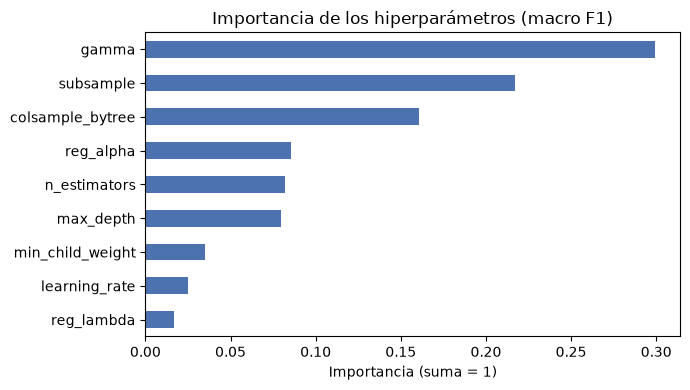

gamma               0.299
subsample           0.217
colsample_bytree    0.161
reg_alpha           0.085
n_estimators        0.082
max_depth           0.079
min_child_weight    0.035
learning_rate       0.025
reg_lambda          0.017
dtype: float64

In [41]:
import matplotlib.pyplot as plt
from optuna.importance import get_param_importances

imp = pd.Series(get_param_importances(study)).sort_values()

imp.plot.barh(figsize=(7, 4), color="#4C72B0")
plt.xlabel("Importancia (suma = 1)")
plt.title("Importancia de los hiperparámetros (macro F1)")
plt.tight_layout()
plt.show()

imp.sort_values(ascending=False).round(3)

### Resultados

- Los hiperparámetros con más importancia son `gamma` (0,30), `subsample` (0,22) y `colsample_bytree` (0,16). Entre los tres explican casi el 70 % de las diferencias de nota entre pruebas.
- `learning_rate` sale casi al final (0,025). No es que no importe: Optuna lo concentró pronto en 0,16-0,30, y dentro de ese rango cambiarlo apenas mueve la nota.
- `gamma` importa sobre todo porque valores altos bloquean divisiones y bajan el F1; la mejor prueba usa un `gamma` casi 0 (0,015).
- La importancia es una estimación aproximada y depende de los rangos elegidos: sirve para ver el orden, no los decimales.

#### Elegir los hiperparámetros finales

Como las 10 mejores pruebas empatan en macro F1, elegimos la de **menor gap**: es la que menos memoriza con la misma nota. Es la prueba 96 (macro F1 0,964; gap 0,028).


In [42]:
ELEGIDA = 96
elegida = study.trials[ELEGIDA]

print(f"Prueba {ELEGIDA}: macro F1 = {elegida.value:.4f}, gap = {elegida.user_attrs['gap']:.4f}")
best_params = elegida.params
best_params

Prueba 96: macro F1 = 0.9638, gap = 0.0276


{'n_estimators': 255,
 'learning_rate': 0.22240513290864158,
 'max_depth': 10,
 'min_child_weight': 3,
 'gamma': 0.24070270214386436,
 'subsample': 0.86366572941564,
 'colsample_bytree': 0.5460632689060315,
 'reg_lambda': 0.5938267535387278,
 'reg_alpha': 0.1628792046230102}

### 5.5 Definir el `XGBClassifier` final

Creamos el modelo con los hiperparámetros que elegimos en 5.4 (`best_params`, prueba 96) más los parámetros fijos (`FIXED`):

- `**FIXED`: `objective="multi:softprob"`, `tree_method="hist"`, `enable_categorical=True`, `random_state=42` y `n_jobs=-1`, los mismos de siempre.
- `**best_params`: los 9 hiperparámetros que encontró Optuna (`n_estimators`, `learning_rate`, `max_depth`, `min_child_weight`, `gamma`, `subsample`, `colsample_bytree`, `reg_lambda`, `reg_alpha`).

Los valores iniciales que usábamos antes (300 árboles, `learning_rate` 0,1, `max_depth` 6) ya no se usan.

Esta celda solo crea el modelo; todavía no lo entrena.

In [44]:
model = XGBClassifier(**FIXED, **best_params)
model

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5460632689060315
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: pyth

### Resultados

- El modelo está creado: se ven los hiperparámetros elegidos en 5.4 (por ejemplo `max_depth=10`) y `enable_categorical=True`. Los valores `None` son los parámetros que dejamos con el valor por defecto de XGBoost.
- Todavía **no está entrenado**: no ha visto ningún dato. Lo entrenaremos dentro de la validación cruzada en el Paso 6.

## Paso 6 · Validación cruzada de XGBoost con los hiperparámetros de Optuna

Queremos saber qué nota sacaría el modelo definitivo (con los hiperparámetros de Optuna) con productos que no ha visto, **sin tocar el test**. Para eso usamos la validación cruzada (CV): partimos train en 3 trozos (*folds*) y, tres veces, entrenamos con 2 trozos y medimos con el que queda fuera.

### 6.1 Entrenar el modelo en cada fold

`cross_validate` hace por nosotros el ciclo completo: en cada fold entrena el modelo con 2 trozos y lo mide con el trozo restante.

- `scoring="f1_macro"`: la métrica principal del equipo.
- `params={"sample_weight": sample_weight}`: pasa los pesos del 5.2 al entrenamiento de cada fold, para que el modelo no ignore las clases pequeñas. (Solo se usan para **entrenar**; la nota se calcula sin pesos, con la fórmula normal.)
- `return_train_score=True`: calcula también la nota sobre los datos con los que entrenó el fold. Lo necesitamos para el gap.

In [49]:
from sklearn.model_selection import cross_validate

scores = cross_validate(
    model, X, y_xgb,
    groups=groups,
    cv=cv,
    scoring="f1_macro",
    params={"sample_weight": sample_weight},
    return_train_score=True,
)

pd.DataFrame({
    "macro F1 train": scores["train_score"],
    "macro F1 validación": scores["test_score"],
}, index=range(1, 4)).round(3)

,macro F1 train,macro F1 validación
1,0.992,0.965
2,0.992,0.964
3,0.991,0.963


### Resultados

- Los 3 folds dan un macro F1 de validación de 0,965, 0,964 y 0,963: el resultado no depende del trozo que se deja fuera.
- El macro F1 de train es ≈ 0,991 en los tres folds, unos 2,7 puntos por encima de la validación.

### 6.2 Nota final y gap

Resumimos los 3 folds en un solo número:

- **Macro F1 de validación (media de los 3 folds)**: la nota honesta del modelo con productos nuevos.
- **Macro F1 de train (media)**: la nota sobre los datos con los que entrenó.
- **Gap** = train − validación. Si es grande, el modelo memoriza en vez de aprender (overfitting). Nuestro límite es **< 5 %**.

In [50]:
train_mean = scores["train_score"].mean()
val_mean = scores["test_score"].mean()
val_std = scores["test_score"].std()
gap = train_mean - val_mean

print(f"macro F1 train:      {train_mean:.3f}")
print(f"macro F1 validación: {val_mean:.3f} (± {val_std:.3f})")
print(f"gap:                 {gap:.3f}  ({gap * 100:.1f} puntos)")

macro F1 train:      0.991
macro F1 validación: 0.964 (± 0.001)
gap:                 0.028  (2.8 puntos)


### Resultados

- Macro F1 de train: 0,991. Macro F1 de validación: 0,964 (± 0,001 entre los 3 folds).
- **Gap = 0,028 (2,8 puntos), por debajo del 5 % fijado.** No hay overfitting preocupante.
- Para saber si esta nota es mejor que la de XGBoost con los hiperparámetros iniciales, la comparamos en el 6.3 con los mismos 3 folds.
- Ojo: 0,96 es una nota alta. En parte se debe a que Open Food Facts calcula NOVA con reglas basadas en los mismos ingredientes y aditivos que usamos como variables (limitación ya anotada en el EDA). Lo revisaremos en el análisis de errores.

### 6.3 Línea base con los mismos 3 folds

Para saber si los hiperparámetros que encontró Optuna mejoran el modelo, medimos el mismo XGBoost con sus hiperparámetros iniciales (300 árboles, `learning_rate` 0,1, `max_depth` 6) con **los mismos 3 folds, los mismos pesos y la misma métrica**. Así la comparación es justa.

`base` es XGBoost con los hiperparámetros iniciales (los de `FIXED` más los tres valores iniciales). `s_base` es su validación cruzada con `cv`. La tabla pone las dos notas, la de los hiperparámetros iniciales y la de los de Optuna, una junto a la otra.

In [51]:
base = XGBClassifier(**FIXED, n_estimators=300, learning_rate=0.1, max_depth=6)

s_base = cross_validate(
    base, X, y_xgb,
    groups=groups, cv=cv,
    scoring="f1_macro",
    params={"sample_weight": sample_weight},
    return_train_score=True,
)

pd.DataFrame({
    "macro F1 validación": [s_base["test_score"].mean(), scores["test_score"].mean()],
    "gap": [s_base["train_score"].mean() - s_base["test_score"].mean(), gap],
}, index=["XGBoost (iniciales)", "XGBoost (Optuna)"]).round(3)

,macro F1 validación,gap
XGBoost (iniciales),0.963,0.025
XGBoost (Optuna),0.964,0.028


### Resultados

- XGBoost con hiperparámetros iniciales (300 árboles, `learning_rate` 0,1, `max_depth` 6): macro F1 de validación 0,963 (± 0,001) y gap 0,025.
- XGBoost con los hiperparámetros de Optuna (prueba 96): macro F1 de validación 0,964 (± 0,001) y gap 0,028.
- La mejora es de 0,001 en macro F1, dentro del ruido entre folds, y el gap sube 0,3 puntos. **Los hiperparámetros de Optuna no mejoran de forma medible a los iniciales**: XGBoost ya estaba cerca del techo que permiten los datos (NOVA se calcula con reglas sobre los mismos ingredientes y aditivos).
- Los dos cumplen el límite del equipo (gap < 5 %). 

## Paso 7 · Recall por clase y matriz de confusión
### 7.1 Predicciones de validación cruzada
El macro F1 resume las 4 clases en un solo número. Para ver dónde se equivoca
el modelo necesitamos sus predicciones. `cross_val_predict` usa los mismos 3 folds:
cada producto se predice con un modelo que **no lo vio** al entrenar.
Así miramos errores reales, sin tocar el test.

In [52]:
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(
    model, X, y_xgb, groups=groups, cv=cv,
    params={"sample_weight": sample_weight},
) + 1                      # volvemos de 0-3 a 1-4 (NOVA)
y_true = y_xgb + 1

pred = X[["pnns_groups_2"]].copy()
pred["NOVA real"] = y_true.values
pred["NOVA predicho"] = y_pred
pred.sample(10, random_state=42)

,pnns_groups_2,NOVA real,NOVA predicho
28976,Milk and yogurt,1,3
771,Chocolate products,4,4
17171,Fats,2,2
30841,Fats,2,2
42573,Dressings and sauces,2,2
32827,Fats,2,2
22990,Teas and herbal teas and coffees,4,4
42118,Dressings and sauces,4,4
35560,Dairy desserts,4,4
44238,Sweetened beverages,4,4


### Resultados
Muestra de 10 productos: 9 aciertos. El error es un producto lácteo
NOVA 1 predicho como NOVA 3. Es solo una muestra; para medir el modelo
calculamos el recall y la precisión de cada clase.

### 7.2 Recall y precisión por clase
El **recall** de una clase responde: de todos los productos que *son* de
esa clase, ¿cuántos encontró el modelo? La **precisión** responde: de los
que el modelo *dijo* que eran de esa clase, ¿cuántos lo eran de verdad?
Miramos sobre todo la NOVA 2, que es la clase más pequeña y la más difícil.

In [53]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true, y_pred, labels=[1, 2, 3, 4], zero_division=0, digits=3,
))

              precision    recall  f1-score   support

           1      0.946     0.983     0.964      4952
           2      0.994     0.993     0.993      4308
           3      0.897     0.956     0.926      7865
           4      0.989     0.956     0.972     21370

    accuracy                          0.964     38495
   macro avg      0.956     0.972     0.964     38495
weighted avg      0.965     0.964     0.964     38495



### Resultados
La NOVA 2 es la mejor clase (recall 0,993): sus productos (aceites, grasas,
azúcar) son fáciles de reconocer. Los puntos más débiles son la precisión de
la NOVA 3 (0,897) y el recall de la NOVA 4 (0,956). El macro F1 (0,964)
coincide con el de la validación cruzada.

### 7.3 Matriz de confusión
Cada fila es la clase **real** y cada columna la clase **predicha**. La diagonal
son los aciertos. Fuera de la diagonal vemos qué clases se confunden.
A la izquierda con el número de productos; a la derecha en porcentaje de cada
fila (es decir, el recall de cada clase en la diagonal).

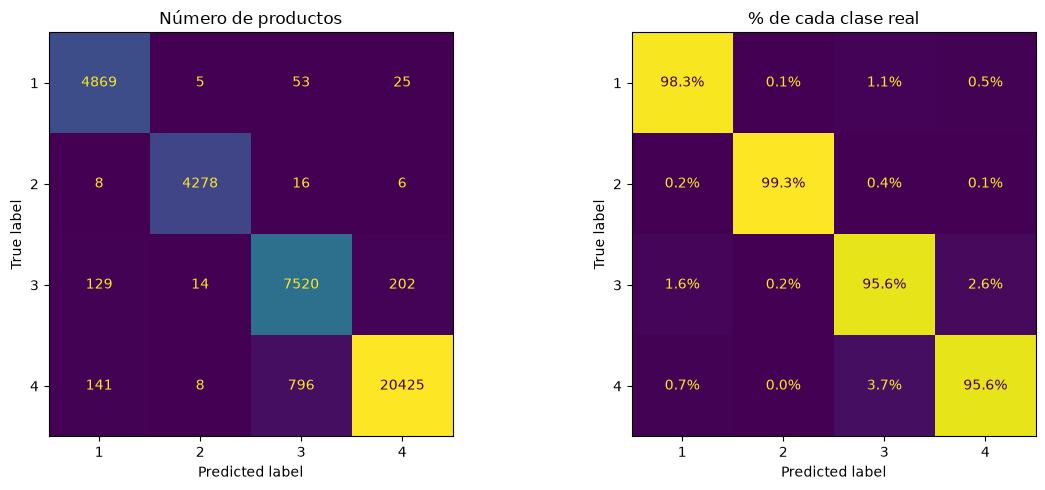

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[1, 2, 3, 4], values_format="d",
    ax=axes[0], colorbar=False,
)
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[1, 2, 3, 4], normalize="true",
    values_format=".1%", ax=axes[1], colorbar=False,
)
axes[0].set_title("Número de productos")
axes[1].set_title("% de cada clase real")
plt.tight_layout()
plt.show()

## Paso 8 · Análisis de errores
### 8.1 ¿Dónde se equivoca el modelo?
Buscamos qué tienen en común los productos mal clasificados. Primero miramos
en qué tipos de producto (`pnns_groups_2`) se concentran los errores:
número de errores, total de productos y porcentaje de error.

In [56]:
pred["error"] = pred["NOVA real"] != pred["NOVA predicho"]
print(f"{pred['error'].sum()} errores de {len(pred)} ({pred['error'].mean():.1%})")

(pred.groupby("pnns_groups_2", observed=True)["error"]
     .agg(errores="sum", total="count", porcentaje="mean")
     .query("total >= 100")
     .sort_values("errores", ascending=False)
     .head(10)
     .style.format({"porcentaje": "{:.1%}"}))

1403 errores de 38495 (3.6%)


,errores,total,porcentaje
pnns_groups_2,,,
unknown,257,5293,4.9%
Bread,123,1314,9.4%
Milk and yogurt,113,1430,7.9%
Cheese,93,1368,6.8%
Cereals,83,1621,5.1%
Breakfast cereals,74,896,8.3%
Sweets,72,3403,2.1%
Legumes,71,556,12.8%
Biscuits and cakes,65,2652,2.5%


### Resultados
El modelo falla en 1.403 de 38.495 productos (3,6 %). El grupo `unknown` tiene
más errores (257) pero porque es grande: su tasa (4,9 %) es parecida a la media.
Las tasas más altas están en `Legumes` (12,8 %), `Bread` (9,4 %),
`Breakfast cereals` (8,3 %), `Milk and yogurt` (7,9 %) y `Cheese` (6,8 %): son
alimentos que pueden ser NOVA 3 o NOVA 4 según la receta. `Sweets` (2,1 %) y
`Biscuits and cakes` (2,5 %) casi siempre son NOVA 4, así que fallan poco.

### 8.2 Productos mal clasificados a mano
Miramos 8 productos de la confusión principal: NOVA 4 real predicho como 3.
Leemos sus ingredientes para entender por qué el modelo dudó.

In [57]:
pd.set_option("display.max_colwidth", 250)

casos = pred[(pred["NOVA real"] == 4) & (pred["NOVA predicho"] == 3)]
casos.join(train[["product_name", "ingredients_text"]]).sample(8, random_state=42)[
    ["product_name", "pnns_groups_2", "ingredients_text"]
]

,product_name,pnns_groups_2,ingredients_text
41168,Chocolate Mousse,unknown,"Søtstoffer (erytritol. steviolglykosider), piskeemulgator (glukose, kokosolje, emulgator: melkesyreestere av mono - og diglyserider av fettsyrer, melkeprotein, stabilisator: natriumalginat), inulin (sikorirotfiber), fettredusert kakao (15%), fort..."
46677,Pitas,Bread,"Harina de TRIGO fortificada (harina de TRIGO, carbonato de calcio, hierro, niacina, ácido fólico, tiamina), agua, levadura, sal, gluten (TRIGO), aceite vegetal (aceite de nabina), conservante (propionato de calcio)"
2691,Feuilles de Filo,Cereals,"Farine de _blé_, eau, amidon de maïs, _gluten de blé_, sel, conservateur : sorbate de potassium, agent de traitement de la farine : L-cystéine."
32910,Tortitas de espelta con chocolate negro,Cereals,"Chocolate negro (pasta de cacao, azúcar, manteca de cacao, vainilla en polvo) (61%), granos de espelta (38,7%), sal marina, emulgente (lecitina de soja)."
3188,Végétal Falafels,unknown,"Pois chiches précuits 45% (eau, pois chiches), fèves 12%, oignons, huiles végétales (colza et tournesol) en proportion variable, eau, farine de _blé_, coriandre 3%, menthe douce 2,5%, fécule de pomme de terre, conservateur : vinaigre tamponné, pe..."
44943,Medallones de Salmón,Fish and seafood,"Salmón (77%), calabaza asada, harina de maíz y trigo (GLUTEN), proteína y fibra de guisante, agua, almidón, sal, azúcar y concentrado de remolacha."
23060,Caldo vegetal,unknown,"Sal del Himalaya, verduras (19%) (zanahoria, chirivia, puerro, apio, boletus), maltodextrina*, hierbas aromáticas (perifollo, levistico, perejil) aceite de girasol*, especias* (pimienta, pimentón dulce, jengibre, curcuma, ajo, nuez moscada)."
40478,Pollo al Curry con Arroz + Grande,One-dish meals,"Pechuga de pollo 33.4%, arroz basmati 8.93%, aceite de oliva, agua, sal, ajo, cebolla, manzana, mantequilla, leche sin lactosa, nata sin lactosa, tomate frito, zumo de limón, canela, curry amarillo 0.71%, colorante, caldo de carne, pimienta negra..."


### Resultados
Los 8 productos tienen en común que parecen alimentos "casi normales": no
tienen muchos aditivos y un solo detalle los convierte en NOVA 4
(maltodextrina, proteína de guisante, lecitina, colorante, edulcorantes). El
modelo ve `additives_n` y las columnas `tiene_*`, pero no conoce todas esas
sustancias. Además, las listas de ingredientes están en varios idiomas
(noruego, español, francés), lo que podría hacer fallar las palabras clave
(hipótesis, sin comprobar). Algunas etiquetas son discutibles (tortitas,
falafels): parte del error es ruido en el objetivo, no un fallo del modelo.

### 8.3 ¿Y si quitamos las variables de ingredientes?
Open Food Facts calcula NOVA a partir de los ingredientes y aditivos. Para ver
cuánto depende nuestro 0,96 de eso, repetimos la validación cruzada **sin**
`additives_n`, `n_ingredientes`, `sin_lista_ingredientes` y las columnas
`tiene_*`. Quedan la categoría del producto y los valores nutricionales.

In [58]:
cols_ingr = ["additives_n", "n_ingredientes", "sin_lista_ingredientes"] + [
    c for c in X.columns if c.startswith("tiene_")
]
print("Quitamos", len(cols_ingr), "columnas:", cols_ingr)

s = cross_validate(
    model, X.drop(columns=cols_ingr), y_xgb, groups=groups, cv=cv,
    scoring="f1_macro", params={"sample_weight": sample_weight},
    return_train_score=True,
)
val, train_ = s["test_score"].mean(), s["train_score"].mean()
print(f"macro F1 validación: {val:.3f} | train: {train_:.3f} | gap: {train_ - val:.3f}")

Quitamos 16 columnas: ['additives_n', 'n_ingredientes', 'sin_lista_ingredientes', 'tiene_aromas', 'tiene_edulcorantes', 'tiene_jarabes', 'tiene_almidon_modificado', 'tiene_proteina_aislada', 'tiene_colorantes', 'tiene_emulsionantes', 'tiene_potenciadores', 'tiene_aceite_palma', 'tiene_conservantes', 'tiene_sal', 'tiene_azucar', 'tiene_aceite']
macro F1 validación: 0.862 | train: 0.976 | gap: 0.115


### Resultados
Sin las 16 variables derivadas de los ingredientes, el macro F1 de validación
baja de 0,964 a 0,862 (train 0,976, gap 0,115). El modelo no se hunde: con solo
la categoría y los valores nutricionales ya llega a 0,862, así que no se limita
a copiar la regla de Open Food Facts. Las variables de ingredientes aportan
unos 10 puntos, lo esperable porque NOVA se define con ingredientes y aditivos.
El gap sube porque este modelo, ajustado para la versión completa, memoriza más
el train; no importa porque el modelo final conserva esas variables.

### 8.4 Prueba con etiquetas mezcladas
Mezclamos al azar las etiquetas NOVA: ya no hay relación real entre el producto
y su clase. Si el modelo sigue sacando una nota alta en validación, hay un fallo
o una fuga. Lo esperado es un macro F1 cercano al azar (~0,25 con 4 clases).

In [59]:
from sklearn.utils.class_weight import compute_sample_weight

rng = np.random.default_rng(42)
y_mez = pd.Series(rng.permutation(y_xgb.values), index=y_xgb.index)
w_mez = compute_sample_weight("balanced", y_mez)

s = cross_validate(
    model, X, y_mez, groups=groups, cv=cv, scoring="f1_macro",
    params={"sample_weight": w_mez}, return_train_score=True,
)
print(f"macro F1 validación: {s['test_score'].mean():.3f} | train: {s['train_score'].mean():.3f}")

macro F1 validación: 0.246 | train: 0.874


### Resultados
Con las etiquetas mezcladas, el macro F1 de validación es 0,246: el azar para
4 clases. El train sube a 0,874 porque el modelo memoriza ruido. Esto descarta
un error en la validación o una fuga entre train y validación: el 0,964 viene
de una relación real entre las variables y NOVA.